In [65]:
import pandas as pd
import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [67]:
df=pd.read_csv("../Datasets/unsw_train.csv")

In [69]:
print("train :", df.shape)
for i in range (len(df.columns)):
    diff=0
    if(df.columns[i]!=df.columns[i]):
        diff+=1
print("Colonnes differentes entre train et test :", diff)
display(df.head(3))
print(df.dtypes.value_counts())

train : (82332, 45)
Colonnes differentes entre train et test : 0


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0


int64      30
float64    11
object      4
Name: count, dtype: int64


In [83]:
SEUIL_CONST = 0.97   # une valeur dominante au-delà de ce taux = quasi constante
SEUIL_CORR = 0.9    # corrélation au-delà de laquelle on supprime une des deux colonnes

y = df["label"]
X = df.drop(columns=["id", "attack_cat", "label"])

# Colonnes quasi constantes
quasi_const = [c for c in X.columns
               if X[c].value_counts(normalize=True).iloc[0] > SEUIL_CONST]
X = X.drop(columns=quasi_const)
print("Quasi constantes :", quasi_const)

#Utilité de chaque feature numérique pour prédire label
num = X.select_dtypes("number")
mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)

# Paires corrélées (Pearson), de la plus forte à la plus faible
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (upper.stack()
              .loc[lambda s: s > SEUIL_CORR]
              .sort_values(ascending=False))
print("Nbrs de paires corrélées :", len(pairs))

# Pour chaque paire, on supprime la moins informative des deux
dropped = set()
for (a, b), r in pairs.items():
    if a in dropped or b in dropped:
        continue                      # paire déjà résolue
    loser = a if mi[a] < mi[b] else b
    dropped.add(loser)
    print(f"{a} vs {b} (r={r:.2f}) -> on supprime {loser}")

X = X.drop(columns=list(dropped))

print("\nQuasi constantes :", quasi_const)
print("Corrélées supprimées :", sorted(dropped))
print("Features restantes :", X.shape[1])
print(list(X.columns))

Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Nbrs de paires corrélées : 15
dbytes vs dloss (r=1.00) -> on supprime dloss
sbytes vs sloss (r=1.00) -> on supprime sloss
ct_srv_src vs ct_srv_dst (r=0.98) -> on supprime ct_srv_src
dpkts vs dbytes (r=0.98) -> on supprime dpkts
spkts vs sbytes (r=0.97) -> on supprime spkts
ct_dst_ltm vs ct_src_dport_ltm (r=0.96) -> on supprime ct_dst_ltm
swin vs dwin (r=0.96) -> on supprime dwin
ct_dst_src_ltm vs ct_srv_dst (r=0.94) -> on supprime ct_dst_src_ltm
tcprtt vs synack (r=0.94) -> on supprime tcprtt
ct_src_dport_ltm vs ct_src_ltm (r=0.93) -> on supprime ct_src_ltm
ct_src_dport_ltm vs ct_dst_sport_ltm (r=0.91) -> on supprime ct_src_dport_ltm

Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Corrélées supprimées : ['ct_dst_ltm', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_src', 'dloss', 'dpkts', 'dwin', 'sloss', 'spkts', 'tcprtt']
Features restantes : 28
['dur', 'proto', 'service', 'state', 

### RandomForest V1

['dur', 'proto', 'service', 'state', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_state_ttl', 'ct_dst_sport_ltm', 'ct_flw_http_mthd', 'ct_srv_dst']
Features restantes : 28

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.5506     0.5506  1.0000  0.7102   0.5000
RF train             0.9968     0.9980  0.9961  0.9971   0.9998
RF validation        0.9504     0.9708  0.9381  0.9542   0.9907
RF test              0.9500     0.9698  0.9384  0.9538   0.9909
validation: VN=5358  FP=192  FN=421  VP=6379
test: VN=5351  FP=199  FN=419  VP=6381


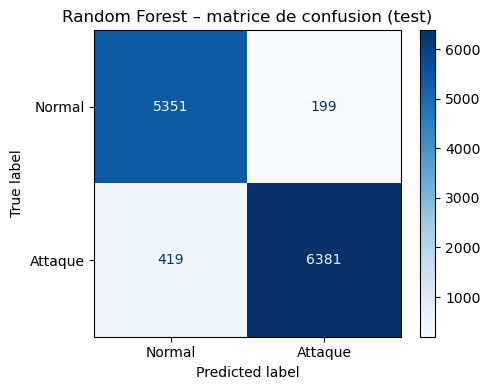

num__sttl            0.0762
num__sbytes          0.0750
num__ct_state_ttl    0.0695
num__ct_srv_dst      0.0690
num__smean           0.0628
num__sload           0.0578
num__rate            0.0502
cat__state_INT       0.0477
num__dbytes          0.0453
num__synack          0.0440
dtype: float64


In [85]:
# 1. Train / validation / test (70 / 15 / 15)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

# 2. Jeux de données
features = X.columns
print(list(X.columns))
print("Features restantes :", X.shape[1])
cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles : baseline majoritaire + Random Forest
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),  # regroupe les protos rares
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("Random Forest – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))

### RandomForest V2 : correction du potentiel dataleakage


Features retenues : 28

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.5506     0.5506  1.0000  0.7102   0.5000
RF train             0.9968     0.9980  0.9961  0.9971   0.9998
RF validation        0.9504     0.9708  0.9381  0.9542   0.9907
RF test              0.9500     0.9698  0.9384  0.9538   0.9909
validation: VN=5358  FP=192  FN=421  VP=6379
test: VN=5351  FP=199  FN=419  VP=6381


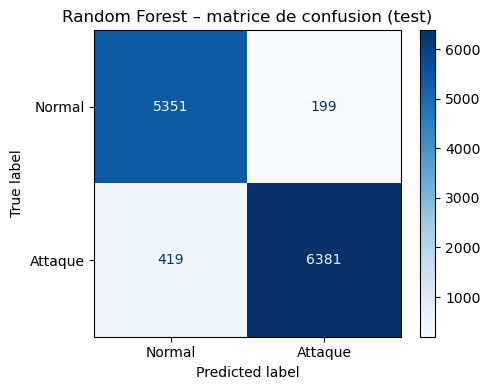

num__sttl            0.0762
num__sbytes          0.0750
num__ct_state_ttl    0.0695
num__ct_srv_dst      0.0690
num__smean           0.0628
num__sload           0.0578
num__rate            0.0502
cat__state_INT       0.0477
num__dbytes          0.0453
num__synack          0.0440
dtype: float64


In [89]:
# 1. Sélection des features V2 que sur le Train
y = train_df["label"]
X = train_df.drop(columns=["id", "attack_cat", "label"])
quasi_const = [c for c in X.columns
               if X[c].value_counts(normalize=True).iloc[0] > 0.97]
X = X.drop(columns=quasi_const)
num = X.select_dtypes("number")
mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
dropped = set()
for (a, b), r in pairs.items():
    if a in dropped or b in dropped:
        continue
    else:
        dropped.add(a if mi[a] < mi[b] else b)
features = [c for c in X.columns if c not in dropped]
print("\nFeatures retenues :", len(features))

# 2. Jeux de données
cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles : baseline majoritaire + Random Forest
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),  # regroupe les protos rares
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("Random Forest – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))

### RandomForest V3 : ajout de 'ct_dst_src_ltm'


Features retenues : 28

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.5506     0.5506  1.0000  0.7102   0.5000
RF train             0.9971     0.9981  0.9965  0.9973   0.9999
RF validation        0.9618     0.9722  0.9579  0.9650   0.9937
RF test              0.9653     0.9738  0.9628  0.9683   0.9946
validation: VN=5364  FP=186  FN=286  VP=6514
test: VN=5374  FP=176  FN=253  VP=6547


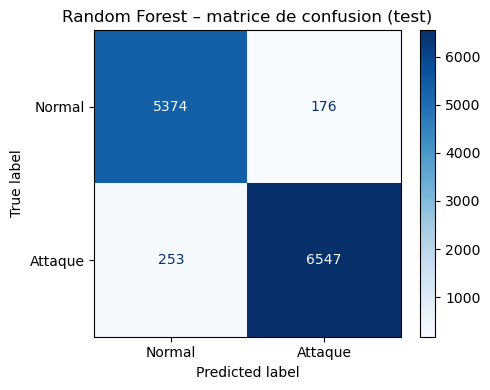

num__ct_dst_src_ltm      0.1055
num__sttl                0.0781
num__ct_state_ttl        0.0683
num__sbytes              0.0661
num__smean               0.0556
num__sload               0.0548
num__rate                0.0496
cat__state_INT           0.0473
num__ct_dst_sport_ltm    0.0470
num__dbytes              0.0417
dtype: float64


In [75]:
# 1. Sélection des features V2 avec 'ct_dst_src_ltm'
FORCE_KEEP = ["ct_dst_src_ltm"]   # voir remarque plus bas ; mettre [] pour comparer

y = train_df["label"]
X = train_df.drop(columns=["id", "attack_cat", "label"])
quasi_const = [c for c in X.columns
               if c not in FORCE_KEEP
               and X[c].value_counts(normalize=True).iloc[0] > 0.97]
X = X.drop(columns=quasi_const)
num = X.select_dtypes("number")
mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
dropped = set()
for (a, b), r in pairs.items():
    if a in dropped or b in dropped:
        continue
    if a in FORCE_KEEP:        # on ne supprime jamais une colonne protégée
        dropped.add(b)
    elif b in FORCE_KEEP:
        dropped.add(a)
    else:
        dropped.add(a if mi[a] < mi[b] else b)
features = [c for c in X.columns if c not in dropped]
print("\nFeatures retenues :", len(features))

# 2. Jeux de données
cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles : baseline majoritaire + Random Forest
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),  # regroupe les protos rares
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("Random Forest – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))